# ICQF test (ordinal / quantized data): training, transforming, and dimension estimation

This notebook mirrors `demo_ICQF.ipynb`, but the raw data is **projected onto 6 discrete
scale levels** `[0, 0.2, 0.4, 0.6, 0.8, 1.0]` — i.e. a 6-point ordinal (Likert-style)
questionnaire. Bounded, discrete responses like these are exactly the setting ICQF's
interval constraints are designed for.

The flow is the same as the continuous walkthrough:

1. Build & **quantize** a `MatrixData` from a pandas DataFrame
2. **Train** with `fit_transform` and inspect the factors
3. **Transform** new rows with the learned loadings fixed
4. (optional) Adjust for confounds
5. **Estimate the embedding dimension** with bi-cross-validation (BCV)
6. **Confound handling** on quantized data: additive baseline vs. regressing it out

Everything runs inline in this process — no cluster/swarm dispatch.

In [1]:
import sys
from pathlib import Path

# This notebook lives in testing/; add the repo root to sys.path so `import icqf`
# (and _generate_examples, used in the confound section) resolve.
_root = Path.cwd()
if not (_root / 'icqf').exists() and (_root.parent / 'icqf').exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from icqf import ICQF, MatrixData, estimate_dimension

rng = np.random.RandomState(0)

# 6-point ordinal scale that the data is projected onto
LEVELS = np.array([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

def quantize(x, levels=LEVELS):
    """Snap each finite entry of x to the nearest scale level; NaN is preserved."""
    x = np.asarray(x, dtype=float)
    nan = np.isnan(x)
    xf = np.where(nan, 0.0, x)
    q = levels[np.abs(xf[..., None] - levels).argmin(axis=-1)]
    return np.where(nan, np.nan, q)

## 1. Data

We build the same synthetic, sparse, low-rank nonnegative matrix as the continuous walkthrough,
then **project it onto the 6-point ordinal scale** with `quantize`. The result looks like
a 6-level questionnaire. In practice you would load your own ordinal data with
`pd.read_csv("my_data.csv", index_col=0)` (rescaled into `[0, 1]`).

In [2]:
n, p, k_true = 200, 30, 4
W_true = rng.rand(n, k_true)
Q_true = (rng.rand(p, k_true) > 0.5) * rng.rand(p, k_true)   # sparse item loadings
M = W_true @ Q_true.T
M = M / M.max()                      # scale into [0, 1] (ICQF default M upper bound = 1)
M = M + rng.randn(n, p) * 0.06       # additive observation noise
M = np.clip(M, 0.0, 1.0)
M = quantize(M)                      # project onto the 6-point ordinal scale

M_df = pd.DataFrame(
    M,
    index=[f"subject_{i:03d}" for i in range(n)],
    columns=[f"item_{j:02d}" for j in range(p)],
)

# randomly mark ~5% of entries as unobserved
miss = rng.rand(n, p) < 0.05
M_df = M_df.mask(miss)

levels_seen = np.unique(M_df.values[~np.isnan(M_df.values)])
print(f"shape={M_df.shape}, missing entries={int(M_df.isna().sum().sum())}, levels={levels_seen}")
M_df.iloc[:4, :6]

shape=(200, 30), missing entries=325, levels=[0.  0.2 0.4 0.6 0.8 1. ]


,item_00,item_01,item_02,item_03,item_04,item_05
subject_000,0.2,0.6,0.4,0.0,0.4,0.0
subject_001,0.2,0.6,0.2,0.0,NaN,NaN
subject_002,0.0,0.8,0.4,0.0,0.4,0.0
subject_003,0.2,0.6,0.2,0.0,0.2,0.0


## 2. Train (`fit_transform`)

`MatrixData.from_frames` validates the frame (unique labels, no all-NaN row/column),
splits it into a value matrix plus an observation mask, and keeps the labels for
label-aware outputs. The fitted `FactorState` carries DataFrame views: `W_df`, `Q_df`,
`Z_df`.

In [3]:
data = MatrixData.from_frames(M_df)

model = ICQF(
    n_components=4,
    W_beta=0.01,
    Q_beta=0.01,
    regularizer=1,      # 1 = L1 (sparsity), 2 = L2
    max_iter=200,
    random_state=0,
)
state, history = model.fit_transform(data)

print("W (subject scores):", state.W_df.shape)
print("Q (item loadings): ", state.Q_df.shape)
state.W_df.head()

W (subject scores): (200, 4)
Q (item loadings):  (30, 4)


,factor_1,factor_2,factor_3,factor_4
sample_id,,,,
subject_000,0.378631,0.246937,0.188325,0.231598
subject_001,0.248643,0.218961,0.251831,0.240135
subject_002,0.552493,0.362563,0.267695,0.000000
subject_003,0.690903,0.000000,0.013321,0.103369
subject_004,0.025741,0.447033,0.063877,0.441033


In [4]:
state.Q_df.head()

,factor_1,factor_2,factor_3,factor_4
feature,,,,
item_00,0.167530,0.000000,0.000000,0.472951
item_01,0.776304,0.759638,0.223608,0.546834
item_02,0.421434,0.000701,0.586276,0.002019
item_03,0.014036,0.007431,0.000000,0.150712
item_04,0.000000,0.501453,0.579253,0.566129


The loss `history` is a list of `(total, mismatch, regularization)` per iteration.

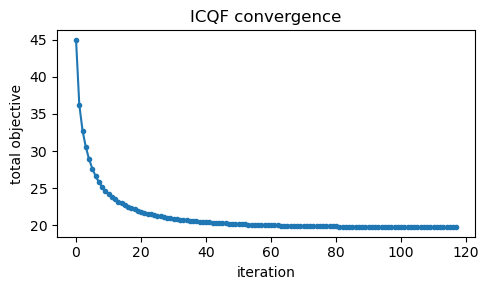

In [5]:
total = [h[0] for h in history]
plt.figure(figsize=(5, 3))
plt.plot(total, marker=".")
plt.xlabel("iteration"); plt.ylabel("total objective"); plt.title("ICQF convergence")
plt.tight_layout(); plt.show()

### Reconstruction

`state.Z_df` is the bounded reconstruction. We can also form `W Q^\top` directly and
check the fit on the *observed* entries.

In [6]:
recon = state.W_df.values @ state.Q_df.values.T
obs = ~M_df.isna().values
rmse = np.sqrt(np.mean((M_df.values[obs] - recon[obs]) ** 2))
print(f"observed-entry RMSE = {rmse:.4f}")
state.Z_df.iloc[:4, :6]

observed-entry RMSE = 0.0748


feature,item_00,item_01,item_02,item_03,item_04,item_05
sample_id,,,,,,
subject_000,0.172972,0.650285,0.270616,0.042054,0.364011,0.006242
subject_001,0.155213,0.546983,0.253085,0.041301,0.391620,0.005843
subject_002,0.092577,0.764188,0.390011,0.010454,0.336889,0.005893
subject_003,0.164619,0.595888,0.299166,0.025275,0.066252,0.003649


### Did we recover the loadings Q?

Factor order and scale are not identified (ICQF may permute factors and trade scale between
`W` and `Q`), so we column-normalize both `Q`s and align the estimated factors to the true
ones by correlation before plotting. The observed matrix `M` is shown with missing entries
(`NaN`) in gray rather than white.

mean matched true-vs-estimated factor correlation = 0.554


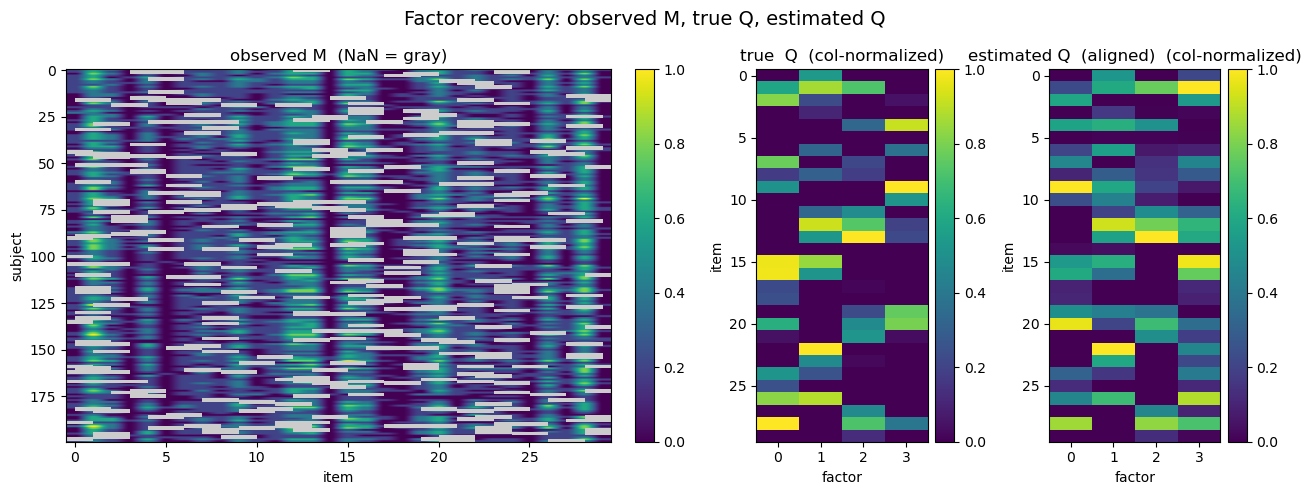

In [7]:
# --- align estimated factors to the true ones (order & scale are not identified) ---
def _norm_cols(A):
    A = np.asarray(A, dtype=float)
    m = A.max(axis=0, keepdims=True); m[m == 0] = 1.0
    return A / m

Qt = _norm_cols(Q_true)               # true loadings, column-normalized
Qe = _norm_cols(state.Q_df.values)    # estimated loadings, column-normalized

corr = np.corrcoef(Qt.T, Qe.T)[:Qt.shape[1], Qt.shape[1]:]   # true x estimated
corr = np.nan_to_num(corr, nan=-1.0)
perm, avail = [], list(range(Qe.shape[1]))
for t in range(Qt.shape[1]):                                  # greedy best match per true factor
    j = avail[int(np.argmax(corr[t, avail]))]
    perm.append(j); avail.remove(j)
Qe = Qe[:, perm]
print(f"mean matched true-vs-estimated factor correlation = "
      f"{np.mean([corr[t, perm[t]] for t in range(Qt.shape[1])]):.3f}")

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("0.8")                                           # NaN -> light gray (not white)

fig, axs = plt.subplots(1, 3, figsize=(13, 5), gridspec_kw={"width_ratios": [3, 1, 1]})
im0 = axs[0].imshow(np.ma.masked_invalid(M_df.values), aspect="auto", cmap=cmap)
axs[0].set_title("observed M  (NaN = gray)"); axs[0].set_xlabel("item"); axs[0].set_ylabel("subject")
fig.colorbar(im0, ax=axs[0], fraction=0.046, pad=0.04)

for ax, Qm, ttl in [(axs[1], Qt, "true  Q"), (axs[2], Qe, "estimated Q  (aligned)")]:
    im = ax.imshow(Qm, aspect="auto", cmap="viridis", vmin=0, vmax=1)
    ax.set_title(ttl + "  (col-normalized)"); ax.set_xlabel("factor"); ax.set_ylabel("item")
    ax.set_xticks(range(Qm.shape[1]))
    fig.colorbar(im, ax=ax, fraction=0.10, pad=0.04)

fig.suptitle("Factor recovery: observed M, true Q, estimated Q", fontsize=14)
fig.tight_layout()
plt.show()

## 3. Transform new rows

`transform` infers `W` (and the reconstruction `Z`) for new samples while keeping the
trained item loadings `Q` **fixed**. Useful for embedding hold-out subjects into the
same factor space.

In [8]:
M_new_df = M_df.iloc[:15].copy()                 # pretend these are unseen subjects
new_state, _ = model.transform(MatrixData.from_frames(M_new_df))
print("inferred W for new rows:", new_state.W_df.shape)
new_state.W_df.head()

inferred W for new rows: (15, 4)


,factor_1,factor_2,factor_3,factor_4
sample_id,,,,
subject_000,0.373140,0.247986,0.190354,0.235994
subject_001,0.242031,0.219877,0.253853,0.245631
subject_002,0.548393,0.364715,0.271897,0.000000
subject_003,0.692972,0.000000,0.013009,0.104004
subject_004,0.014190,0.447813,0.067513,0.449211


## 4. (optional) Confound adjustment

If you have a fully observed design matrix `C` (samples × confounds, same index as `M`),
pass it as `C_df`. ICQF then fits $M \approx W Q^\top + C Q_c^\top$ and exposes `state.Qc_df`.

Because the confound loadings are non-negative, encode a bounded covariate together with its
complement — e.g. `age` **and** `1 − age` — so the baseline can trend either up or down
(see section 6). Here we use `C = [intercept, age, 1 − age]`.

In [9]:
age = rng.rand(n)                                    # a confound in [0, 1]
C_df = pd.DataFrame(
    {"intercept": 1.0, "age": age, "one_minus_age": 1.0 - age},
    index=M_df.index,
)
data_c = MatrixData.from_frames(M_df, C_df=C_df)
model_c = ICQF(n_components=4, random_state=0, max_iter=200)
state_c, _ = model_c.fit_transform(data_c)
print("Qc (confound loadings):", None if state_c.Qc_df is None else state_c.Qc_df.shape)
state_c.Qc_df.head()

Qc (confound loadings): (30, 3)


confound,intercept,age,one_minus_age
feature,,,
item_00,0.081487,0.000000,0.005370
item_01,0.277252,0.019059,0.000000
item_02,0.146806,0.000000,0.000000
item_03,0.023253,0.000000,0.004769
item_04,0.181678,0.000000,0.000000


## 5. Estimate the embedding dimension (BCV)

The number of factors is chosen by **bi-cross-validation**. For each candidate rank `k`:

- split the observed entries into `J` folds,
- for each fold, mask that fold's entries to `NaN` (held-out *test* entries), fit ICQF on
  the rest, and measure reconstruction error on the held-out entries.

Train error keeps falling as `k` grows; the **held-out (test) error** bottoms out near the
true rank and then rises as extra components start fitting noise. `estimate_dimension`
runs the whole sweep serially in this process.

In [10]:
results_df, summary_df, best_k = estimate_dimension(
    M_df,
    dimension_list=[2, 3, 4, 5, 6, 8, 10],
    J=5,
    repeat=2,
    random_state=42,
    icqf_kwargs=dict(W_beta=0.01, Q_beta=0.01, regularizer=1, max_iter=150),
    verbose=False,
)
print(f"estimated best dimension = {best_k}  (true rank = {k_true})")
summary_df

estimated best dimension = 4  (true rank = 4)


,n_components,test_mse_mean,test_mse_std,test_mse_se_raw,train_mse_mean,train_mse_std,train_mse_se,n_replicates,test_mse_se_paired,test_mse_se
0,2,0.011127,0.000430,0.000136,0.008728,0.000189,0.000060,10,0.000136,0.000136
1,3,0.009360,0.000351,0.000111,0.006494,0.000083,0.000026,10,0.000062,0.000062
2,4,0.008140,0.000445,0.000141,0.005171,0.000115,0.000036,10,0.000103,0.000103
3,5,0.008832,0.000509,0.000161,0.004841,0.000124,0.000039,10,0.000096,0.000096
4,6,0.009708,0.000651,0.000206,0.004492,0.000090,0.000029,10,0.000106,0.000106
5,8,0.011386,0.000743,0.000235,0.003906,0.000103,0.000033,10,0.000128,0.000128
6,10,0.013224,0.000639,0.000202,0.003361,0.000113,0.000036,10,0.000125,0.000125


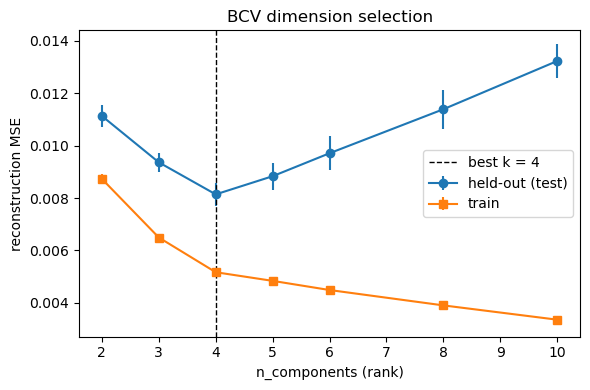

In [11]:
plt.figure(figsize=(6, 4))
plt.errorbar(summary_df["n_components"], summary_df["test_mse_mean"],
             yerr=summary_df["test_mse_std"], marker="o", label="held-out (test)")
plt.errorbar(summary_df["n_components"], summary_df["train_mse_mean"],
             yerr=summary_df["train_mse_std"], marker="s", label="train")
plt.axvline(best_k, color="k", ls="--", lw=1, label=f"best k = {best_k}")
plt.xlabel("n_components (rank)"); plt.ylabel("reconstruction MSE")
plt.title("BCV dimension selection"); plt.legend()
plt.tight_layout(); plt.show()

## 6. Confound handling: additive baseline vs. regressing it out

A common alternative is to **regress the confound out first** — fit an age effect per item
and factorize the residuals. Those residuals are mean-centered and routinely go
**negative**, which is awkward for a non-negative questionnaire and breaks the
non-negativity the factor model relies on.

ICQF instead folds the confound *into* the factorization as a **non-negative additive
baseline** $C Q_c^\top \ge 0$, so the part the factors must explain is the non-negative
remainder $W Q^\top = Z - C Q_c^\top \ge 0$ — it stays inside the questionnaire's own range.

**Modeling both increasing *and* decreasing trends.** ICQF requires non-negative confound
loadings ($Q_c \ge 0$), so a single `age` column can only *raise* the baseline with age — it
can never represent a *decreasing* trend. We therefore give the design matrix the complement
`1 − age` as well: a non-negative loading on `1 − age` contributes a decreasing term. With
`C = [intercept, age, 1 − age]`, non-negative combinations span any straight-line baseline
— constant, increasing, or decreasing — that stays $\ge 0$.

We build items with age trends of *both* signs, fit ICQF with this `C_df`, and compare the
two views for one representative item.

In [12]:
from _generate_examples import simulation

np.random.seed(0)
n_c, p_c, k_c = 200, 60, 10
W_c = simulation(n_c, ncol=k_c, ndict=k_c)          # (n, k) block-structured subject scores
Q_c = simulation(p_c, ncol=k_c, ndict=k_c)          # (p, k) block-structured item loadings

age = np.random.rand(n_c)                            # confound, rescaled to [0, 1]

# per-item age trends with BOTH signs; the level keeps each baseline >= 0 on [0, 1]
slope_true = np.random.uniform(-0.4, 0.4, p_c)
level_true = np.abs(slope_true) + np.random.uniform(0.05, 0.20, p_c)
baseline_true = level_true[None, :] + np.outer(age, slope_true)    # (n, p), >= 0

# design matrix: intercept, age, and its complement (1 - age) -> baseline can tilt either way
C = np.column_stack([np.ones(n_c), age, 1.0 - age])

M_c = W_c @ Q_c.T + baseline_true + np.random.randn(n_c, p_c) * 0.01
M_c = np.clip(M_c, 0.0, None)
M_c = M_c / M_c.max()                                # scale into [0, 1]
M_c = quantize(M_c)                                  # project onto the 6-point ordinal scale
Mc_df = pd.DataFrame(M_c, index=[f"subject_{i:03d}" for i in range(n_c)],
                     columns=[f"item_{j:02d}" for j in range(p_c)])
Cc_df = pd.DataFrame(C, index=Mc_df.index, columns=["intercept", "age", "one_minus_age"])

print("M:", Mc_df.shape, " C:", Cc_df.shape, "[intercept, age, 1-age]", " factors k =", k_c)
Mc_df.iloc[:4, :5]

M: (200, 60)  C: (200, 3) [intercept, age, 1-age]  factors k = 10


,item_00,item_01,item_02,item_03,item_04
subject_000,0.4,0.6,0.4,0.4,0.4
subject_001,0.4,0.6,0.4,0.4,0.4
subject_002,0.4,0.6,0.4,0.4,0.4
subject_003,0.4,0.4,0.4,0.4,0.4


In [13]:
model_conf = ICQF(n_components=k_c, W_beta=0.01, Q_beta=0.01, random_state=0, max_iter=250)
state_conf, _ = model_conf.fit_transform(MatrixData.from_frames(Mc_df, C_df=Cc_df))

baseline_full = Cc_df.values @ state_conf.Qc_df.values.T          # C Qc^T  (the additive baseline)
factor_full   = state_conf.W_df.values @ state_conf.Q_df.values.T  # W Q^T   (what the factors explain)

print("additive baseline  C·Qc^T  >= 0 :", bool((baseline_full >= -1e-9).all()))
print("factor remainder   W·Q^T   >= 0 :", bool((factor_full   >= -1e-9).all()))

# with [intercept, age, 1-age] the baseline's age-slope can take either sign:
base_slopes = np.polyfit(age, baseline_full, 1)[0]
print(f"fitted baseline age-slopes span {base_slopes.min():+.3f} .. {base_slopes.max():+.3f}  "
      f"({np.mean(base_slopes < 0):.0%} of items decreasing) — a single 'age' column could only give >= 0")
state_conf.Qc_df.head()

additive baseline  C·Qc^T  >= 0 : True
factor remainder   W·Q^T   >= 0 : True
fitted baseline age-slopes span -0.227 .. +0.329  (52% of items decreasing) — a single 'age' column could only give >= 0


confound,intercept,age,one_minus_age
feature,,,
item_00,0.122842,0.088083,0.000000
item_01,0.199169,0.255506,0.000000
item_02,0.039757,0.000000,0.194281
item_03,0.000000,0.000000,0.058129
item_04,0.065391,0.039467,0.040049


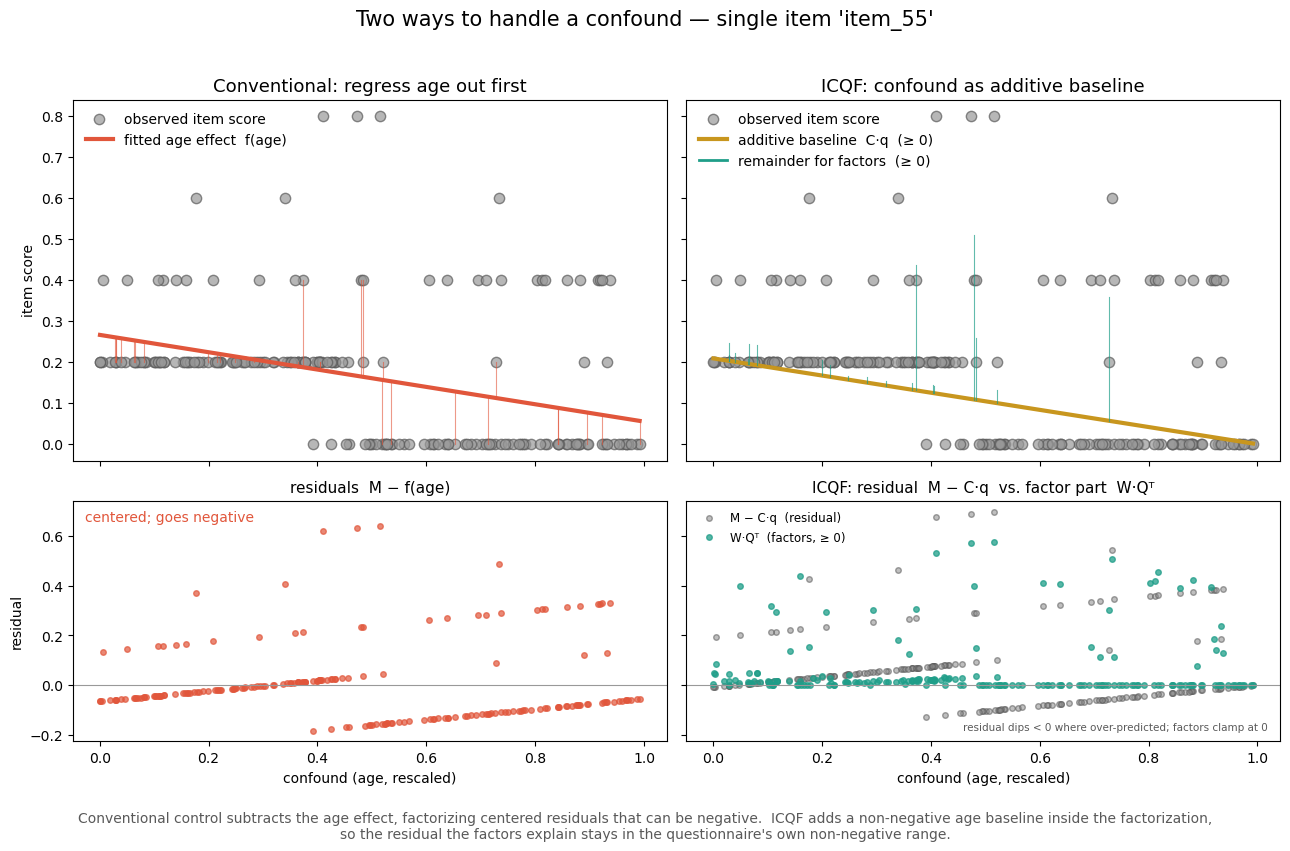

In [14]:
# representative item: strong factor structure AND a decreasing baseline, to show the
# (1 - age) column letting the additive baseline tilt downward (impossible with age alone)
fac_std = factor_full.std(axis=0)
strong  = np.where(fac_std >= np.quantile(fac_std, 0.75))[0]
i = int(strong[np.argmin(base_slopes[strong])])
y = Mc_df.values[:, i]
slope, intercept = np.polyfit(age, y, 1)
fit_line = intercept + slope * age          # conventional age regression
ols_res  = y - fit_line                     # residuals (can be negative)
baseline = baseline_full[:, i]              # ICQF additive baseline (>= 0)
factor   = factor_full[:, i]                # remainder the factors explain (>= 0)

order = np.argsort(age)
sub   = np.random.RandomState(1).choice(n_c, 30, replace=False)   # stems for a subset

# scatter panels on top; residual / factor panels as their own row below (no overlap)
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex="col", sharey="row",
                         gridspec_kw={"height_ratios": [3, 2]})
(axTL, axTR), (axBL, axBR) = axes
fig.suptitle(f"Two ways to handle a confound \u2014 single item '{Mc_df.columns[i]}'", fontsize=15)

# --- Top-left: conventional regress-age-out ---
axTL.scatter(age, y, s=55, c="0.6", edgecolor="0.35", alpha=.7, label="observed item score")
axTL.plot(age[order], fit_line[order], c="#e1563b", lw=3, label="fitted age effect  f(age)")
for j in sub:
    axTL.plot([age[j]] * 2, [fit_line[j], y[j]], c="#e1563b", lw=.8, alpha=.6)
axTL.set_title("Conventional: regress age out first", fontsize=13)
axTL.set_ylabel("item score"); axTL.legend(loc="upper left", frameon=False)

# --- Top-right: ICQF additive non-negative baseline ---
axTR.scatter(age, y, s=55, c="0.6", edgecolor="0.35", alpha=.7, label="observed item score")
axTR.plot(age[order], baseline[order], c="#c8961e", lw=3, label="additive baseline  C·q  (≥ 0)")
for j in sub:
    axTR.plot([age[j]] * 2, [baseline[j], baseline[j] + factor[j]], c="#1f9e89", lw=.8, alpha=.7)
axTR.plot([], [], c="#1f9e89", lw=2, label="remainder for factors  (≥ 0)")
axTR.set_title("ICQF: confound as additive baseline", fontsize=13)
axTR.legend(loc="upper left", frameon=False)

# --- Bottom-left: conventional residuals (go negative) ---
axBL.scatter(age, ols_res, s=16, c="#e1563b", alpha=.7)
axBL.axhline(0, c="0.6", lw=.8)
axBL.set_title("residuals  M − f(age)", fontsize=11)
axBL.set_xlabel("confound (age, rescaled)"); axBL.set_ylabel("residual")
axBL.text(.02, .96, "centered; goes negative", color="#e1563b", ha="left", va="top",
          fontsize=10, transform=axBL.transAxes)

# --- Bottom-right: ICQF residual  M − C·q  vs. the factor part  W·Qᵀ ---
axBR.scatter(age, y - baseline, s=16, c="0.55", edgecolor="0.35", alpha=.55,
             label="M − C·q  (residual)")
axBR.scatter(age, factor, s=16, c="#1f9e89", alpha=.75, label="W·Qᵀ  (factors, ≥ 0)")
axBR.axhline(0, c="0.6", lw=.8)
axBR.set_title("ICQF: residual  M − C·q  vs. factor part  W·Qᵀ", fontsize=11)
axBR.set_xlabel("confound (age, rescaled)")
axBR.legend(loc="upper left", frameon=False, fontsize=8.5)
axBR.text(.98, .04, "residual dips < 0 where over-predicted; factors clamp at 0",
          color="0.35", ha="right", va="bottom", fontsize=7.5, transform=axBR.transAxes)

fig.tight_layout(rect=[0, 0.05, 1, 0.96])
fig.text(.5, .005,
    "Conventional control subtracts the age effect, factorizing centered residuals that can be negative.  "
    "ICQF adds a non-negative age baseline inside the factorization,\n"
    "so the residual the factors explain stays in the questionnaire's own non-negative range.",
    ha="center", fontsize=10, color="0.35")
plt.show()

### Why the baseline often sits near zero (and how to loosen it)

You may notice the fitted baseline hugging the *floor* of the data rather than its mean —
and collapsing toward 0 for an item as soon as a few subjects have a zero entry. This is
structural, not a bug:

- The baseline $C Q_c^\top \ge 0$ is an **additive** term that the **non-negative** factors
  $W Q^\top \ge 0$ sit *on top of*, so for every subject `reconstruction = baseline + factor ≥ baseline`.
- A subject with a zero entry can only be fit well if the baseline is ≈ 0 there (the factors
  can add, never subtract). Under squared error a few zeros pull the baseline down, and —
  because the factors already explain everything *above* the floor — nothing pushes it back
  up. The baseline behaves like a **lower envelope (≈ per-item minimum), not a mean.**

Ways to loosen it:

1. **Richer confound basis** (done here): `[intercept, age, 1 − age]` lets the baseline *tilt*,
   so a zero at one end of the age range no longer forces the whole item's baseline to 0 — it
   can stay high where the data is high. Splines / bins of age generalize this.
2. **Lighter regularization on `Qc`.** The confound loadings are L1-penalized together with `Q`
   (via `Q_beta`); a large `Q_beta` actively drives them to 0. Lower it to let the baseline grow.
3. **Fewer factors.** With a smaller `n_components`, the factors cannot soak up every
   above-floor pattern, so the baseline must carry more of the level.

The deeper point: you *cannot* make this non-negative baseline track the conditional **mean**
without letting the remainder go negative — that is exactly the regression behavior the left
panel shows. The floor-like baseline is the price of keeping the remainder non-negative.

*In the figure this is also why some observed points fall **below** the gold baseline: those subjects are over-predicted. The factors can only add, so the reconstruction `baseline + W·Qᵀ` can never reach below the baseline — the gap shows up as a negative fit residual `M − Z`, not as a negative factor. The bottom-right panel shows **both**: the residual `M − C·q` (gray), which dips slightly below 0 for those over-predicted subjects, and the factor part `W·Qᵀ` (teal), which is ≥ 0 by construction. They differ exactly by the full-model residual: `M − C·q = W·Qᵀ + (M − Z)`.*

## Notes

- **Scaling.** ICQF's default reconstruction upper bound is `1.0` (`M_upperbd=(True, 1.0)`),
  so scale `M` into `[0, 1]` (or pass a different bound) for best results.
- **Real data.** Replace the synthetic block in section 1 with
  `M_df = pd.read_csv("my_data.csv", index_col=0)`; the rest is unchanged.
- **Scale / parallelism.** Dimension selection here is a single-process serial loop, which
  is sufficient for one survey-sized matrix. Large-scale parallel BCV dispatch (cluster /
  swarm) is intentionally omitted from this public standalone.
- **Ordinal data.** Here the data is quantized to 6 levels `[0, 0.2, …, 1.0]`; the `M_upperbd=(True, 1.0)` default matches that top level. For a different number of levels or a different max, rescale to `[0, 1]` (or set `M_upperbd` accordingly).